In [2]:
import os

def count_images(path):
    rgb, depth = 0, 0
    for root, _, files in os.walk(path):
        for f in files:
            if f.endswith(".jpg"):
                rgb += 1
            elif f.endswith(".png"):
                depth += 1
    return rgb, depth


train_path = "/kaggle/input/nyu-depth-v2/nyu_data/data/nyu2_train"
test_path  = "/kaggle/input/nyu-depth-v2/nyu_data/data/nyu2_test"

train_rgb, train_depth = count_images(train_path)
test_rgb, test_depth   = count_images(test_path)

print("Train:")
print(" RGB:", train_rgb, " Depth:", train_depth)

print("Test:")
print(" RGB:", test_rgb, " Depth:", test_depth)


Train:
 RGB: 50688  Depth: 50688
Test:
 RGB: 0  Depth: 1308


# Object detection 

In [5]:
%cd /kaggle/working

!wget -O yolov13s.pt https://github.com/iMoonLab/yolov13/releases/download/yolov13/yolov13s.pt


/kaggle/working
--2026-02-15 18:45:20--  https://github.com/iMoonLab/yolov13/releases/download/yolov13/yolov13s.pt
Resolving github.com (github.com)... 140.82.112.4
Connecting to github.com (github.com)|140.82.112.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/1006122056/df06654e-3a17-44c6-87b3-8f70ce941759?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-02-15T19%3A41%3A28Z&rscd=attachment%3B+filename%3Dyolov13s.pt&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-02-15T18%3A40%3A43Z&ske=2026-02-15T19%3A41%3A28Z&sks=b&skv=2018-11-09&sig=kveANXGcXBtz3c4OaKtvB2d8cNEkeXMBIlBw5QEvfpE%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia2V5Ijoia2V5MSIsImV4cCI6MTc3MTE4MjkyMCwibmJmIjoxNzcxMTgxMTIwLCJwYXRoIjoicmVsZWFzZWFzc2V0cHJvZHVjdGl

In [10]:
# %cd /kaggle/working/yolov13

# !wget -O flash_attn-2.7.3+cu11torch2.2cxx11abiFALSE-cp311-cp311-linux_x86_64.whl \
# https://github.com/Dao-AILab/flash-attention/releases/download/v2.7.3/flash_attn-2.7.3+cu11torch2.2cxx11abiFALSE-cp311-cp311-linux_x86_64.whl

# %pip install -r requirements.txt
# %pip install -e .

In [9]:
%cd /kaggle/working/yolov13
!wget -q https://github.com/iMoonLab/yolov13/releases/download/yolov13/yolov13n.pt
!ls -lh yolov13n.pt


/kaggle/working/yolov13
-rw-r--r-- 1 root root 11M Jun 22  2025 yolov13n.pt



image 1/1 /kaggle/input/nyu-depth-v2/nyu_data/data/nyu2_train/basement_0001a_out/236.jpg: 480x640 3 bottles, 4 chairs, 1 oven, 264.3ms
Speed: 1.8ms preprocess, 264.3ms inference, 2.0ms postprocess per image at shape (1, 3, 480, 640)

image 1/1 /kaggle/input/nyu-depth-v2/nyu_data/data/nyu2_train/kitchen_0003_out/54.jpg: 480x640 1 cup, 1 bowl, 1 sink, 1 refrigerator, 254.0ms
Speed: 3.7ms preprocess, 254.0ms inference, 1.5ms postprocess per image at shape (1, 3, 480, 640)

image 1/1 /kaggle/input/nyu-depth-v2/nyu_data/data/nyu2_train/living_room_0069a_out/93.jpg: 480x640 2 chairs, 1 potted plant, 245.3ms
Speed: 1.7ms preprocess, 245.3ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 640)

image 1/1 /kaggle/input/nyu-depth-v2/nyu_data/data/nyu2_train/bathroom_0013_out/8.jpg: 480x640 2 persons, 1 bottle, 1 cup, 1 toilet, 2 sinks, 218.2ms
Speed: 1.9ms preprocess, 218.2ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 640)


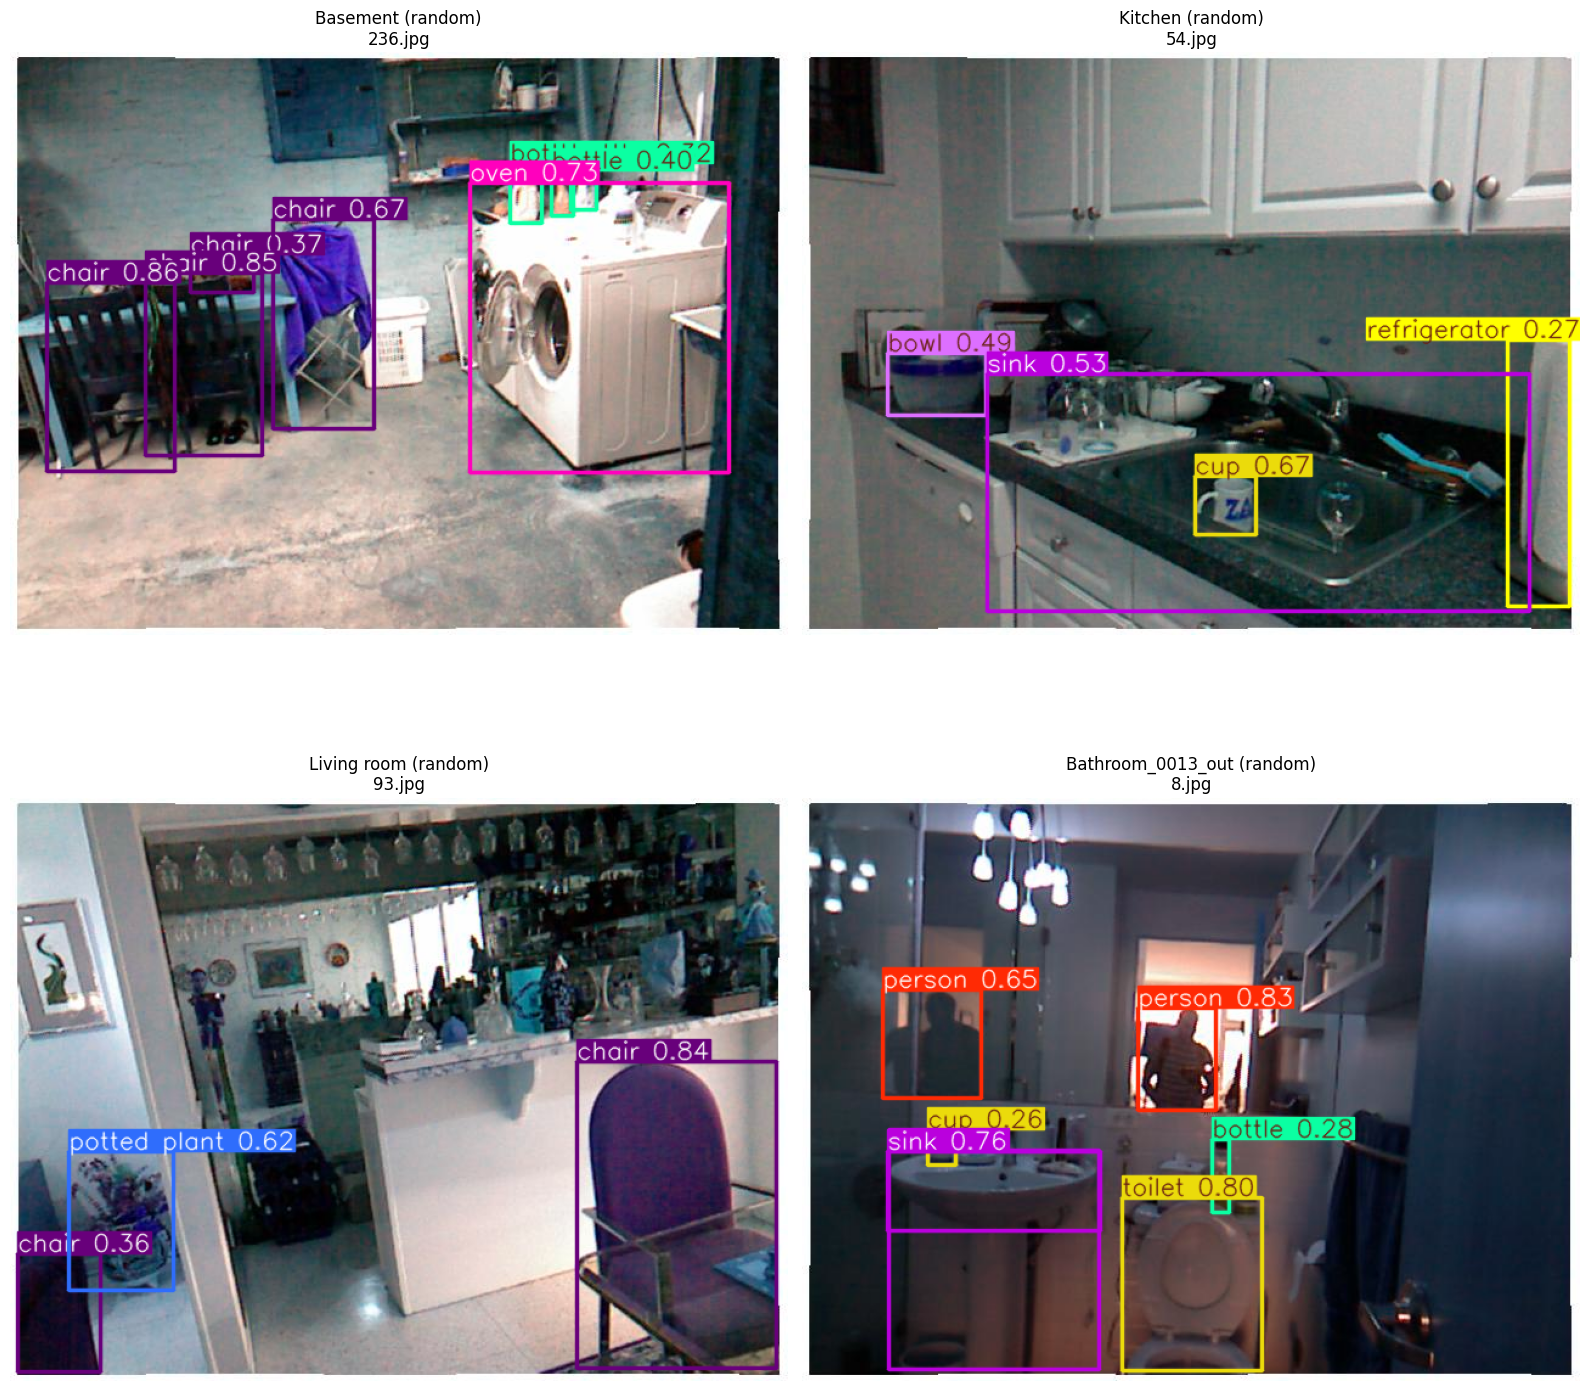

In [ ]:
import glob, random, os
import matplotlib.pyplot as plt
from ultralytics import YOLO

# مدل
model = YOLO("/kaggle/working/yolov13/yolov13n.pt")

base = "/kaggle/input/nyu-depth-v2/nyu_data/data/nyu2_train"

def pick_random_image(folder_glob):
    """Pick a random image from folders matched by folder_glob (jpg preferred, then png)."""
    folders = glob.glob(os.path.join(base, folder_glob))
    imgs = []
    for f in folders:
        imgs += glob.glob(os.path.join(f, "*.jpg"))
    if len(imgs) == 0:
        for f in folders:
            imgs += glob.glob(os.path.join(f, "*.png"))
    return random.choice(imgs) if imgs else None

img_basement = pick_random_image("basement_*_out")
img_kitchen  = pick_random_image("kitchen_*_out")
img_living   = pick_random_image("living_room_*_out")

bath_folder = os.path.join(base, "bathroom_0013_out")
bath_imgs = glob.glob(os.path.join(bath_folder, "*.jpg"))
if len(bath_imgs) == 0:
    bath_imgs = glob.glob(os.path.join(bath_folder, "*.png"))
img_bathroom_0013 = random.choice(bath_imgs) if bath_imgs else None

titles_and_paths = [
    ("Basement (random)", img_basement),
    ("Kitchen (random)", img_kitchen),
    ("Living room (random)", img_living),
    ("Bathroom_0013_out (random)", img_bathroom_0013),
]

plt.figure(figsize=(16, 16))

for i, (title, path) in enumerate(titles_and_paths, start=1):
    plt.subplot(2, 2, i)
    if path is None:
        plt.title(title + " - NOT FOUND")
        plt.axis("off")
        continue

    results = model(path, imgsz=640, conf=0.25)
    plt.imshow(results[0].plot())
    plt.title(f"{title}\n{os.path.basename(path)}")
    plt.axis("off")

plt.tight_layout()
plt.show()


# depth estimation

* some RGB images and depth images 

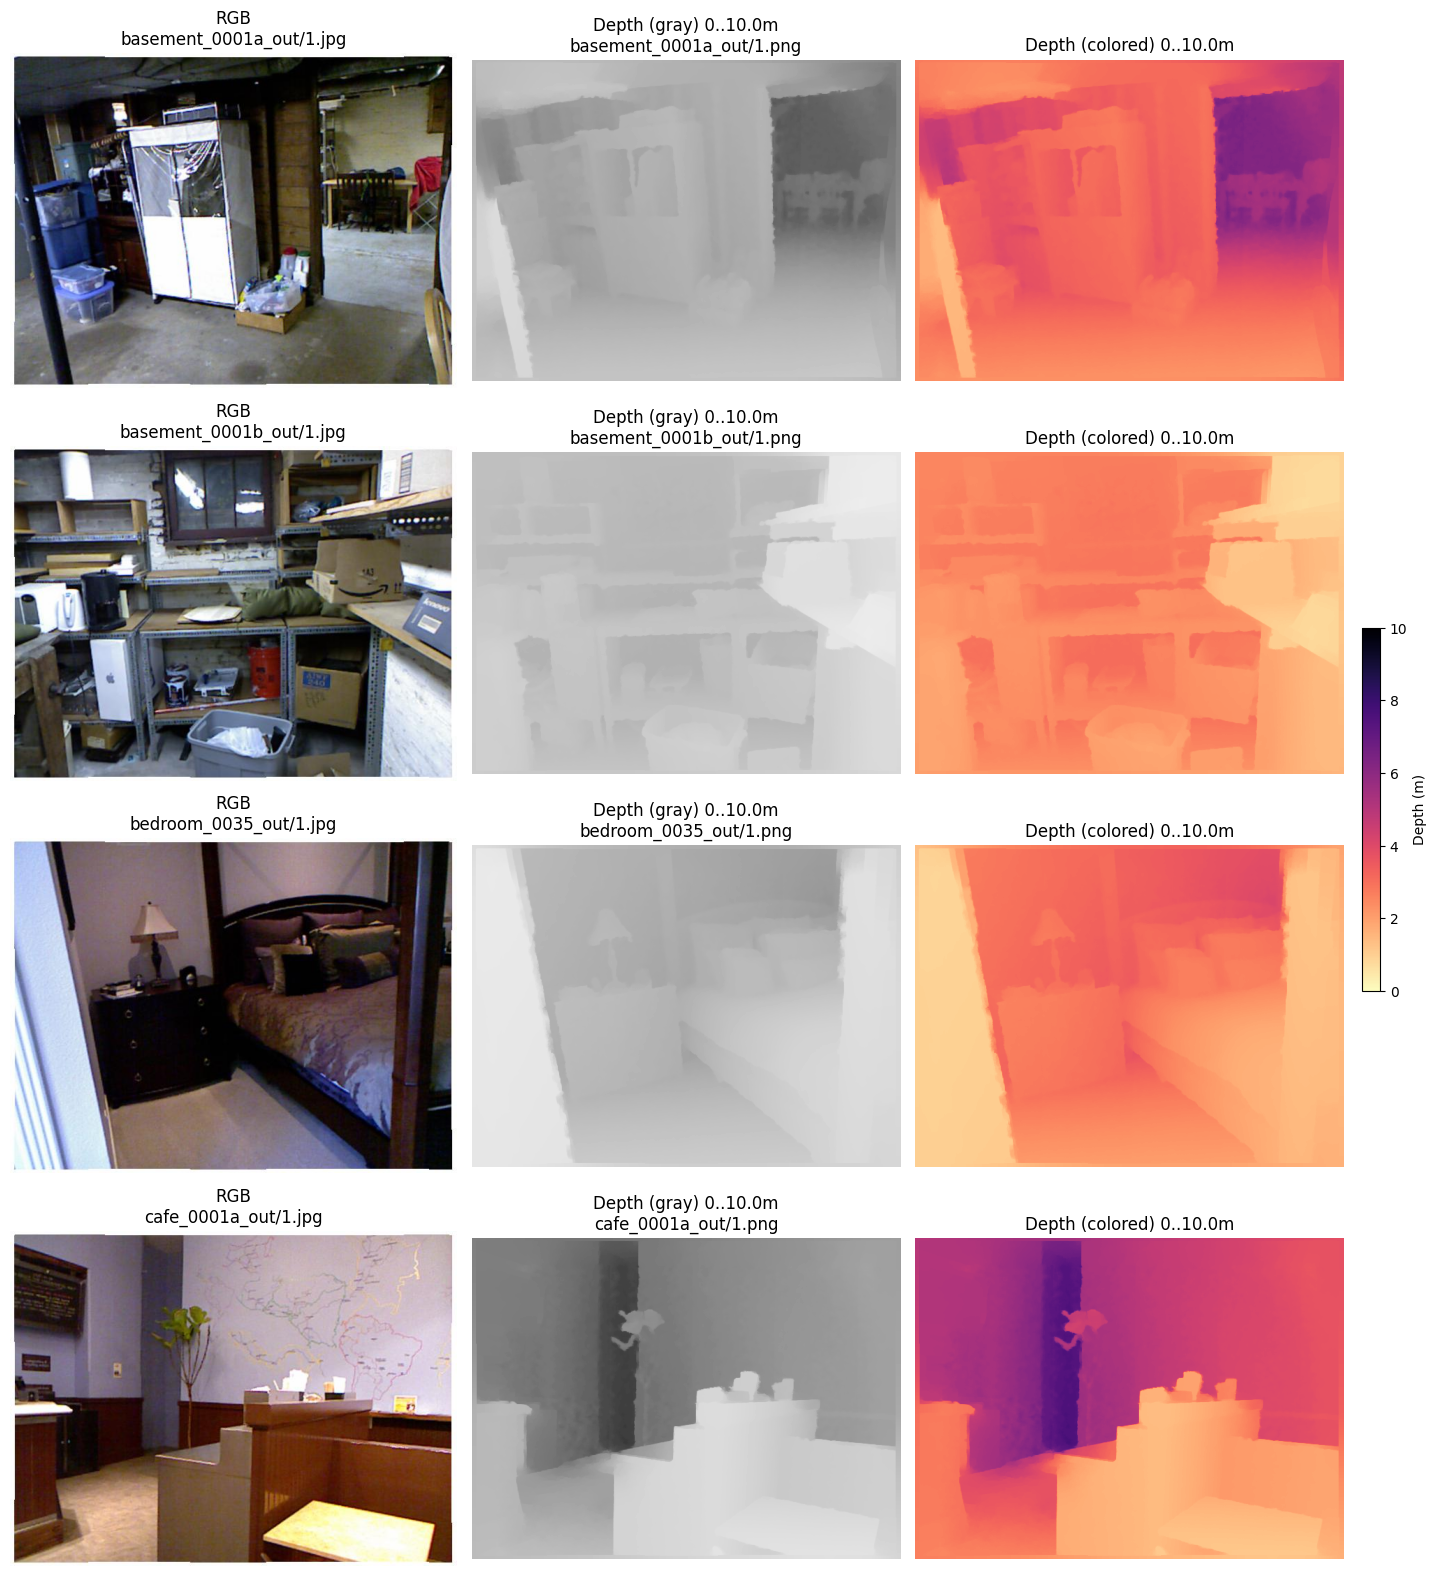

In [ ]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import os

depth_paths = [
    "/kaggle/input/nyu-depth-v2/nyu_data/data/nyu2_train/basement_0001a_out/1.png",
    "/kaggle/input/nyu-depth-v2/nyu_data/data/nyu2_train/basement_0001b_out/1.png",
    "/kaggle/input/nyu-depth-v2/nyu_data/data/nyu2_train/bedroom_0035_out/1.png",
    "/kaggle/input/nyu-depth-v2/nyu_data/data/nyu2_train/cafe_0001a_out/101.png",

]

MAX_DEPTH_M = 10.0  # 0..10 meters

def read_rgb_depth(depth_path):
    rgb_path = os.path.splitext(depth_path)[0] + ".jpg"
    rgb = np.array(Image.open(rgb_path).convert("RGB"))
    d = np.array(Image.open(depth_path))  # uint8 expected
    return rgb_path, rgb, depth_path, d

def depth_to_meters_uint8(d_uint8, max_depth=10.0):
    # فرض: 0..255  ->  0..max_depth meters
    depth_m = d_uint8.astype(np.float32) / 255.0 * max_depth
    return np.clip(depth_m, 0.0, max_depth)

# ساخت شکل 4×3
fig, axes = plt.subplots(len(depth_paths), 3, figsize=(14, 4 * len(depth_paths)))

for i, dp in enumerate(depth_paths):
    try:
        rgb_path, rgb, depth_path, d = read_rgb_depth(dp)
        depth_m = depth_to_meters_uint8(d, MAX_DEPTH_M)

        # 1) RGB
        ax = axes[i, 0]
        ax.imshow(rgb)
        ax.set_title(f"RGB\n{os.path.basename(os.path.dirname(rgb_path))}/1.jpg")
        ax.axis("off")

        # 2) Depth grayscale (farther darker)
        ax = axes[i, 1]
        im1 = ax.imshow(depth_m, cmap="gray_r", vmin=0, vmax=MAX_DEPTH_M)
        ax.set_title(f"Depth (gray) 0..{MAX_DEPTH_M}m\n{os.path.basename(os.path.dirname(depth_path))}/1.png")
        ax.axis("off")

        # 3) Depth colored (farther darker)
        ax = axes[i, 2]
        im2 = ax.imshow(depth_m, cmap="magma_r", vmin=0, vmax=MAX_DEPTH_M)  
        ax.set_title(f"Depth (colored) 0..{MAX_DEPTH_M}m")
        ax.axis("off")

    except Exception as e:
        for j in range(3):
            axes[i, j].text(0.5, 0.5, f"Error:\n{e}", ha="center", va="center")
            axes[i, j].axis("off")

plt.tight_layout()

cbar = fig.colorbar(im2, ax=axes[:, 1:].ravel().tolist(), fraction=0.02, pad=0.02)
cbar.set_label("Depth (m)")

plt.show()


# Model

In [1]:
import math
from dataclasses import dataclass
from typing import Tuple, Dict

import torch
import torch.nn as nn
import torch.nn.functional as F


# -----------------------------
# Utils
# -----------------------------
def conv_bn_act(in_ch, out_ch, k=3, s=1, p=1, groups=1, act=True):
    layers = [
        nn.Conv2d(in_ch, out_ch, k, s, p, groups=groups, bias=False),
        nn.BatchNorm2d(out_ch),
    ]
    if act:
        layers.append(nn.ReLU6(inplace=True))
    return nn.Sequential(*layers)


# -----------------------------
# MobileNetV2-like Inverted Residual (lightweight CNN)
# -----------------------------
class InvertedResidual(nn.Module):
    def __init__(self, in_ch, out_ch, stride, expand_ratio):
        super().__init__()
        assert stride in [1, 2]
        hidden = int(round(in_ch * expand_ratio))
        self.use_res = (stride == 1 and in_ch == out_ch)

        layers = []
        if expand_ratio != 1:
            layers.append(conv_bn_act(in_ch, hidden, k=1, s=1, p=0))

        layers.append(conv_bn_act(hidden, hidden, k=3, s=stride, p=1, groups=hidden))
        layers.append(nn.Conv2d(hidden, out_ch, 1, 1, 0, bias=False))
        layers.append(nn.BatchNorm2d(out_ch))
        self.block = nn.Sequential(*layers)

    def forward(self, x):
        y = self.block(x)
        return y + x if self.use_res else y


class TSTEncoder3(nn.Module):
    """
    Outputs ONLY 3 scales like TST paper's {F1,F2,F3}:
      f1: /8
      f2: /16
      f3: /32
    """
    def __init__(self, c_f1=64, c_f2=128, c_f3=160, width_mult=1.0):
        super().__init__()
        stem = int(32 * width_mult)
        self.stem = conv_bn_act(3, stem, k=3, s=2, p=1)  # /2

        # internal /4 stage (not exposed)
        c4 = int(64 * width_mult)
        self.s1 = nn.Sequential(
            InvertedResidual(stem, c4, stride=2, expand_ratio=1),  # /4
            InvertedResidual(c4, c4, stride=1, expand_ratio=6),
        )
        # /8 -> F1
        self.s2 = nn.Sequential(
            InvertedResidual(c4, c_f1, stride=2, expand_ratio=6),  # /8
            InvertedResidual(c_f1, c_f1, stride=1, expand_ratio=6),
        )
        # /16 -> F2
        self.s3 = nn.Sequential(
            InvertedResidual(c_f1, c_f2, stride=2, expand_ratio=6),  # /16
            InvertedResidual(c_f2, c_f2, stride=1, expand_ratio=6),
        )
        # /32 -> F3
        self.s4 = nn.Sequential(
            InvertedResidual(c_f2, c_f3, stride=2, expand_ratio=6),  # /32
            InvertedResidual(c_f3, c_f3, stride=1, expand_ratio=6),
        )

    def forward(self, x) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        x = self.stem(x)   # /2
        x = self.s1(x)     # /4 (hidden)
        f1 = self.s2(x)    # /8
        f2 = self.s3(f1)   # /16
        f3 = self.s4(f2)   # /32
        return f1, f2, f3


# -----------------------------
# Token-Sharing Transformer (Connection Module)
# FIX: K,V are projected from global channels (can differ from local channels)
# -----------------------------
class CrossAttention(nn.Module):
    def __init__(self, c_q: int, c_kv: int, heads: int, dim_qk=16, dim_v=16):
        super().__init__()
        self.heads = heads
        self.dim_qk = dim_qk
        self.dim_v = dim_v

        # Q from local
        self.q = nn.Conv2d(c_q, heads * dim_qk, 1, bias=False)
        self.q_bn = nn.BatchNorm2d(heads * dim_qk)

        # K,V from global (may have different channels)
        self.k = nn.Conv2d(c_kv, heads * dim_qk, 1, bias=False)
        self.v = nn.Conv2d(c_kv, heads * dim_v,  1, bias=False)
        self.k_bn = nn.BatchNorm2d(heads * dim_qk)
        self.v_bn = nn.BatchNorm2d(heads * dim_v)

        # project back to local channels
        self.proj = nn.Conv2d(heads * dim_v, c_q, 1, bias=False)
        self.proj_bn = nn.BatchNorm2d(c_q)

    def forward(self, x_local, x_global):
        B, _, H, W = x_local.shape
        L = H * W

        q = self.q_bn(self.q(x_local)).view(B, self.heads, self.dim_qk, L)
        k = self.k_bn(self.k(x_global)).view(B, self.heads, self.dim_qk, L)
        v = self.v_bn(self.v(x_global)).view(B, self.heads, self.dim_v,  L)

        attn = torch.matmul(q.permute(0, 1, 3, 2), k) / math.sqrt(self.dim_qk)  # (B,h,L,L)
        attn = F.softmax(attn, dim=-1)

        out = torch.matmul(attn, v.permute(0, 1, 3, 2))  # (B,h,L,dim_v)
        out = out.permute(0, 1, 3, 2).contiguous().view(B, self.heads * self.dim_v, H, W)

        out = self.proj_bn(self.proj(out))
        return out


class FFNLite(nn.Module):
    # 1x1 -> DW 3x3 -> 1x1 (light FFN)
    def __init__(self, c: int, expansion=4):
        super().__init__()
        hidden = max(c, c * expansion)
        self.pw1 = conv_bn_act(c, hidden, k=1, s=1, p=0)
        self.dw  = conv_bn_act(hidden, hidden, k=3, s=1, p=1, groups=hidden)
        self.pw2 = nn.Sequential(
            nn.Conv2d(hidden, c, 1, bias=False),
            nn.BatchNorm2d(c),
        )

    def forward(self, x):
        return self.pw2(self.dw(self.pw1(x)))


class TSTBlock(nn.Module):
    def __init__(self, c_local: int, c_global: int, heads: int, dim_qk=16, dim_v=16):
        super().__init__()
        self.attn = CrossAttention(c_q=c_local, c_kv=c_global, heads=heads, dim_qk=dim_qk, dim_v=dim_v)
        self.ffn  = FFNLite(c_local)

    def forward(self, x_local_ds, x_global):
        x = x_local_ds + self.attn(x_local_ds, x_global)
        x = x + self.ffn(x)
        return x


class TokenSharingConnection(nn.Module):
    """
    Inputs:
      f1 (/8), f2 (/16), f3 (/32)
    Global token is f3.
    """
    def __init__(self, c_f1: int, c_f2: int, c_f3: int):
        super().__init__()
        self.b1 = TSTBlock(c_local=c_f1, c_global=c_f3, heads=2, dim_qk=16, dim_v=16)
        self.b2 = TSTBlock(c_local=c_f2, c_global=c_f3, heads=4, dim_qk=16, dim_v=16)
        self.b3 = TSTBlock(c_local=c_f3, c_global=c_f3, heads=5, dim_qk=16, dim_v=32)

    def forward(self, f1, f2, f3):
        Hg, Wg = f3.shape[-2:]
        g = f3

        f1_ds = F.adaptive_avg_pool2d(f1, (Hg, Wg))
        f2_ds = F.adaptive_avg_pool2d(f2, (Hg, Wg))

        o1 = self.b1(f1_ds, g)
        o2 = self.b2(f2_ds, g)
        o3 = self.b3(f3,    g)

        o1_up = F.interpolate(o1, size=f1.shape[-2:], mode="bilinear", align_corners=False)
        o2_up = F.interpolate(o2, size=f2.shape[-2:], mode="bilinear", align_corners=False)

        return f1 + o1_up, f2 + o2_up, f3 + o3


# -----------------------------
# GLPDepth SFF + 3-scale Decoder
# -----------------------------
class SelectiveFeatureFusion(nn.Module):
    def __init__(self, c=64):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(2 * c, c, 3, 1, 1),
            nn.BatchNorm2d(c),
            nn.ReLU(inplace=True),
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(c, c // 2, 3, 1, 1),
            nn.BatchNorm2d(c // 2),
            nn.ReLU(inplace=True),
        )
        self.conv3 = nn.Conv2d(c // 2, 2, 3, 1, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x_local, x_global):
        x = torch.cat([x_local, x_global], dim=1)
        attn = self.sigmoid(self.conv3(self.conv2(self.conv1(x))))
        return x_local * attn[:, 0:1] + x_global * attn[:, 1:2]


class GLPDecoder3(nn.Module):
    """
    Decoder adapted to 3 scales:
      f3: /32 -> 64 -> up to /16
      fuse with f2 (/16) -> up to /8
      fuse with f1 (/8)  -> upsample to full res
    """
    def __init__(self, c_f1: int, c_f2: int, c_f3: int, out_c: int = 64):
        super().__init__()
        self.bot   = nn.Conv2d(c_f3, out_c, 1)
        self.skip2 = nn.Conv2d(c_f2, out_c, 1)
        self.skip1 = nn.Conv2d(c_f1, out_c, 1)

        self.fuse2 = SelectiveFeatureFusion(out_c)  # /16
        self.fuse1 = SelectiveFeatureFusion(out_c)  # /8

    def forward(self, f1, f2, f3):
        out = F.interpolate(self.bot(f3), scale_factor=2, mode="bilinear", align_corners=False)  # /32->/16
        out = self.fuse2(self.skip2(f2), out)
        out = F.interpolate(out, scale_factor=2, mode="bilinear", align_corners=False)          # /16->/8

        out = self.fuse1(self.skip1(f1), out)

        # /8 -> /4 -> /2 -> /1
        out = F.interpolate(out, scale_factor=2, mode="bilinear", align_corners=False)
        out = F.interpolate(out, scale_factor=2, mode="bilinear", align_corners=False)
        out = F.interpolate(out, scale_factor=2, mode="bilinear", align_corners=False)
        return out


# -----------------------------
# Full TST Depth Model (3-scale)
# -----------------------------
@dataclass
class TSTConfig:
    c_f1: int = 64   # /8
    c_f2: int = 128  # /16
    c_f3: int = 160  # /32
    dec_c: int = 64
    max_depth: float = 10.0


class TSTDepthModel3(nn.Module):
    def __init__(self, cfg: TSTConfig = TSTConfig()):
        super().__init__()
        self.max_depth = cfg.max_depth

        self.encoder = TSTEncoder3(cfg.c_f1, cfg.c_f2, cfg.c_f3)
        self.connection = TokenSharingConnection(cfg.c_f1, cfg.c_f2, cfg.c_f3)

        # optional conv on last feature before decoder
        self.last_conv = conv_bn_act(cfg.c_f3, cfg.c_f3, k=3, s=1, p=1)

        self.decoder = GLPDecoder3(cfg.c_f1, cfg.c_f2, cfg.c_f3, out_c=cfg.dec_c)

        self.depth_head = nn.Sequential(
            nn.Conv2d(cfg.dec_c, cfg.dec_c, 3, 1, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(cfg.dec_c, 1, 3, 1, 1),
        )

    def forward(self, x) -> Dict[str, torch.Tensor]:
        f1, f2, f3 = self.encoder(x)                 # /8, /16, /32
        f1p, f2p, f3p = self.connection(f1, f2, f3)  # token sharing
        f3p = self.last_conv(f3p)

        out = self.decoder(f1p, f2p, f3p)
        depth = torch.sigmoid(self.depth_head(out)) * self.max_depth
        return {"pred_d": depth}


# -----------------------------
# Sanity test (Notebook-friendly)
# -----------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = TSTDepthModel3(TSTConfig()).to(device)
model.eval()

x = torch.randn(1, 3, 480, 640, device=device)
with torch.no_grad():
    y = model(x)["pred_d"]

print("Output:", y.shape, "min/max:", y.min().item(), y.max().item())

model.train()
x = torch.randn(2, 3, 480, 640, device=device)
pred = model(x)["pred_d"]

loss = pred.mean()
loss.backward()

print("backward ok, loss:", loss.item())

Output: torch.Size([1, 1, 480, 640]) min/max: 4.908767223358154 4.9745659828186035
backward ok, loss: 5.023141384124756


# dataset , augmentation

In [ ]:
import os, glob
from pathlib import Path

def find_nyu_data_root():
    base = Path("/kaggle/input")
    for d in base.iterdir():
        cand = d / "nyu_data" / "data"
        if cand.exists():
            return str(cand)

    hits = glob.glob("/kaggle/input/**/nyu_data/data", recursive=True)
    return hits[0] if len(hits) else None

data_root = find_nyu_data_root()
print("data_root:", data_root)
print("contents:", os.listdir(data_root))

train_dir = os.path.join(data_root, "nyu2_train")
test_dir  = os.path.join(data_root, "nyu2_test")
print("train_dir exists:", os.path.exists(train_dir))
print("test_dir exists:", os.path.exists(test_dir))

data_root: /kaggle/input/nyu-depth-v2/nyu_data/data
contents: ['nyu2_train', 'nyu2_train.csv', 'nyu2_test', 'nyu2_test.csv']
train_dir exists: True
test_dir exists: True


In [ ]:
def collect_pairs(root_dir):
    img_paths = sorted(glob.glob(os.path.join(root_dir, "**", "*.jpg"), recursive=True))
    pairs = []
    missing = 0
    for ip in img_paths:
        dp = os.path.splitext(ip)[0] + ".png"
        if os.path.exists(dp):
            pairs.append((ip, dp))
        else:
            missing += 1
    return pairs, missing

train_pairs, miss_tr = collect_pairs(train_dir)
test_pairs,  miss_te = collect_pairs(test_dir)

print("train pairs:", len(train_pairs), "missing depth:", miss_tr)
print("test  pairs:", len(test_pairs),  "missing depth:", miss_te)
print("example:", train_pairs[0])


train pairs: 50688 missing depth: 0
test  pairs: 0 missing depth: 0
example: ('/kaggle/input/nyu-depth-v2/nyu_data/data/nyu2_train/basement_0001a_out/1.jpg', '/kaggle/input/nyu-depth-v2/nyu_data/data/nyu2_train/basement_0001a_out/1.png')


In [ ]:
import numpy as np
from PIL import Image

import torch
from torch.utils.data import Dataset
import torchvision.transforms.functional as TF
from torchvision.transforms import InterpolationMode


class DepthFolderDataset(Dataset):
    """
    pairs: list of (rgb_path, depth_path)
    depth PNG شما uint8 است و به 0..max_depth (meters) نگاشت می‌شود.
    Augmentations مطابق TST:
      - flip p=0.5
      - brightness/contrast/gamma/hue/saturation/value هرکدام p=0.5
      - vertical CutDepth p=0.25
    """

    def __init__(
        self,
        pairs,
        out_hw=(480, 640),
        training=True,
        max_depth=10.0,
        imagenet_norm=True,
        # probabilities (مطابق مقاله)
        p_flip=0.5,
        p_color_each=0.5,
        p_cutdepth=0.25,
        # cutdepth hyperparameter p (داخل معادله GLPDepth)
        cutdepth_p=0.75,
        brightness_delta=0.2,
        contrast_delta=0.2,
        gamma_delta=0.2,            # ±20%  → gamma in [0.8, 1.2]
        hue_degrees=20,             # ±20 degrees → factor in [-20/180, +20/180]
        saturation_delta=0.3,       # ±30%  → sat in [0.7, 1.3]
        value_delta=0.2,            # ±20%  → V in [0.8, 1.2]
    ):
        self.pairs = pairs
        self.out_hw = out_hw
        self.training = training
        self.max_depth = float(max_depth)
        self.imagenet_norm = imagenet_norm

        self.p_flip = float(p_flip)
        self.p_color_each = float(p_color_each)
        self.p_cutdepth = float(p_cutdepth)
        self.cutdepth_p = float(cutdepth_p)

        self.brightness_delta = float(brightness_delta)
        self.contrast_delta = float(contrast_delta)
        self.gamma_delta = float(gamma_delta)
        self.hue_factor = float(hue_degrees) / 180.0
        self.saturation_delta = float(saturation_delta)
        self.value_delta = float(value_delta)

        self.mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        self.std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    def __len__(self):
        return len(self.pairs)

    def _read_depth_meters(self, depth_path: str) -> torch.Tensor:
        dimg = Image.open(depth_path)
        d = np.array(dimg)
        if d.ndim == 3:
            d = d[..., 0]

        if d.dtype == np.uint8:
            depth_m = (d.astype(np.float32) / 255.0) * self.max_depth
        elif d.dtype == np.uint16:
            depth_m = d.astype(np.float32) / 1000.0
        else:
            depth_m = d.astype(np.float32)

        return torch.from_numpy(depth_m).unsqueeze(0)  # (1,H,W)

    def _adjust_value_hsv(self, img: Image.Image, v_factor: float) -> Image.Image:
        hsv = np.array(img.convert("HSV"), dtype=np.uint8)
        v = hsv[..., 2].astype(np.float32) * v_factor
        hsv[..., 2] = np.clip(v, 0, 255).astype(np.uint8)
    
        # بدون mode (رفع warning)
        out = Image.fromarray(hsv)
        return out.convert("RGB")

    def _apply_color_aug(self, img: Image.Image) -> Image.Image:
        # brightness
        if torch.rand(1).item() < self.p_color_each:
            fac = 1.0 + (2*torch.rand(1).item() - 1.0) * self.brightness_delta
            img = TF.adjust_brightness(img, fac)

        # contrast
        if torch.rand(1).item() < self.p_color_each:
            fac = 1.0 + (2*torch.rand(1).item() - 1.0) * self.contrast_delta
            img = TF.adjust_contrast(img, fac)

        # gamma
        if torch.rand(1).item() < self.p_color_each:
            gamma = 1.0 + (2*torch.rand(1).item() - 1.0) * self.gamma_delta
            gamma = max(gamma, 0.01)
            img = TF.adjust_gamma(img, gamma=gamma, gain=1.0)

        # hue
        if torch.rand(1).item() < self.p_color_each:
            hf = (2*torch.rand(1).item() - 1.0) * self.hue_factor
            img = TF.adjust_hue(img, hf)

        # saturation
        if torch.rand(1).item() < self.p_color_each:
            fac = 1.0 + (2*torch.rand(1).item() - 1.0) * self.saturation_delta
            img = TF.adjust_saturation(img, fac)

        # value (HSV V)
        if torch.rand(1).item() < self.p_color_each:
            fac = 1.0 + (2*torch.rand(1).item() - 1.0) * self.value_delta
            img = self._adjust_value_hsv(img, fac)

        return img

    def _vertical_cutdepth(self, img_t: torch.Tensor, depth_m: torch.Tensor) -> torch.Tensor:
        """
        Vertical CutDepth (GLPDepth):
          (l, u) = (α*W, 0)
          (w, h) = (max((W-αW)*β*p, 1), H)
        و در نوار [l:l+w] کل ارتفاع، RGB با depth GT همان ناحیه جایگزین می‌شود.
        """
        _, H, W = img_t.shape
        alpha = torch.rand(1).item()
        beta  = torch.rand(1).item()

        l = int(alpha * W)
        w = int(max((W - alpha * W) * beta * self.cutdepth_p, 1))
        r = min(l + w, W)

        # depth -> [0,1] و در 3 کانال
        patch = (depth_m / self.max_depth).clamp(0.0, 1.0).expand(3, -1, -1)
        img_t[:, :, l:r] = patch[:, :, l:r]
        return img_t

    def __getitem__(self, idx):
        img_path, depth_path = self.pairs[idx]

        img = Image.open(img_path).convert("RGB")
        depth_m = self._read_depth_meters(depth_path)  # (1,H,W)

        # resize مشترک
        H, W = self.out_hw
        img = TF.resize(img, (H, W), interpolation=InterpolationMode.BILINEAR)
        depth_m = TF.resize(depth_m, (H, W), interpolation=InterpolationMode.BILINEAR)

        if self.training:
            # flip (مشترک)
            if torch.rand(1).item() < self.p_flip:
                img = TF.hflip(img)
                depth_m = TF.hflip(depth_m)

            img = self._apply_color_aug(img)

        img_t = TF.to_tensor(img)  # (3,H,W) in [0,1]

        if self.training and (torch.rand(1).item() < self.p_cutdepth):
            img_t = self._vertical_cutdepth(img_t, depth_m)

        # ImageNet normalization
        if self.imagenet_norm:
            img_t = (img_t - self.mean) / self.std

        mask = (depth_m > 0.0) & (depth_m <= self.max_depth) & torch.isfinite(depth_m)
        depth_m = torch.clamp(depth_m, 0.0, self.max_depth)

        return {"image": img_t, "depth": depth_m, "mask": mask.float()}


In [5]:
from torch.utils.data import DataLoader

train_ds = DepthFolderDataset(train_pairs, out_hw=(480,640), training=True, max_depth=10.0)
train_loader = DataLoader(train_ds, batch_size=6, shuffle=True, num_workers=2, pin_memory=True)

batch = next(iter(train_loader))
print(batch["image"].shape, batch["depth"].shape, batch["mask"].shape)
print("depth min/max:", batch["depth"].min().item(), batch["depth"].max().item())
print("valid ratio:", batch["mask"].mean().item())


torch.Size([6, 3, 480, 640]) torch.Size([6, 1, 480, 640]) torch.Size([6, 1, 480, 640])
depth min/max: 0.7058823704719543 8.823529243469238
valid ratio: 1.0


In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MAX_DEPTH = 10.0

model = TSTDepthModel3(TSTConfig(max_depth=MAX_DEPTH)).to(device)
model.train()

batch = next(iter(train_loader))
x = batch["image"].to(device)

pred = model(x)["pred_d"]
print("pred:", pred.shape, pred.min().item(), pred.max().item())


pred: torch.Size([6, 1, 480, 640]) 2.665652275085449 6.468286991119385


# split train , validation

In [7]:
import random

SEED = 42
random.seed(SEED)

pairs = train_pairs[:]   # لیست (rgb, depth)
random.shuffle(pairs)

val_ratio = 0.02  # مثلا 2% برای validation (با 50k میشه ~1000)
n_val = int(len(pairs) * val_ratio)

val_pairs = pairs[:n_val]
tr_pairs  = pairs[n_val:]

print("train:", len(tr_pairs), "val:", len(val_pairs))


train: 49675 val: 1013


# data loader

In [ ]:
import sys

try:
    from torch.utils.data.dataloader import _MultiProcessingDataLoaderIter

    _orig_del = _MultiProcessingDataLoaderIter.__del__

    def _quiet_del(self):
        try:
            _orig_del(self)
        except AssertionError as e:
            if "can only test a child process" in str(e):
                return
            raise
        except Exception:
            return

    _MultiProcessingDataLoaderIter.__del__ = _quiet_del
    print("✅ Suppressed DataLoader shutdown tracebacks.")
except Exception as e:
    print("⚠️ Could not patch DataLoader iterator:", repr(e))

✅ Suppressed DataLoader shutdown tracebacks.


In [9]:
from torch.utils.data import DataLoader

MAX_DEPTH = 10.0
H, W = 480, 640
BATCH_SIZE = 6

train_ds = DepthFolderDataset(
    tr_pairs, out_hw=(H, W),
    training=True, max_depth=MAX_DEPTH,
    imagenet_norm=True,
    p_flip=0.5, p_color_each=0.5, p_cutdepth=0.25
)

val_ds = DepthFolderDataset(
    val_pairs, out_hw=(H, W),
    training=False, max_depth=MAX_DEPTH,
    imagenet_norm=True,
    p_flip=0.0, p_color_each=0.0, p_cutdepth=0.0
)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True,
    persistent_workers=True,   # ✅ کارگرها بین epoch ها نابود/ساخته نشن
    prefetch_factor=2          # ✅ پیش‌فرض 2 هست ولی صریح بهتره
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=2
)


# loss 

In [ ]:
import torch

def tst_scale_invariant_log_loss(pred, gt, mask=None, lam=0.5, eps=1e-6, reduction="mean"):
    """
    Scale-Invariant Log Loss (Eigen):
      d = log(pred) - log(gt)
      L = mean(d^2) - lam * (mean(d))^2

    pred, gt: (B,1,H,W) depth in meters
    mask: (B,1,H,W) 0/1 یا bool (اختیاری)
    lam: معمولاً 0.5 (فرم رایج Eigen)
    """
    pred = torch.clamp(pred, min=eps)
    gt   = torch.clamp(gt,   min=eps)

    if mask is None:
        mask = torch.ones_like(gt, dtype=pred.dtype, device=pred.device)
    else:
        mask = mask.to(dtype=pred.dtype)

    d = torch.log(pred) - torch.log(gt)  # (B,1,H,W)

    # per-image masked mean
    n = mask.sum(dim=(1,2,3))  # (B,)
    n_safe = torch.clamp(n, min=1.0)

    mean_d  = (d * mask).sum(dim=(1,2,3)) / n_safe
    mean_d2 = ((d * d) * mask).sum(dim=(1,2,3)) / n_safe

    loss_per = mean_d2 - lam * (mean_d ** 2)

    valid = (n > 0).to(loss_per.dtype)
    loss_per = loss_per * valid

    if reduction == "mean":
        return loss_per.sum() / torch.clamp(valid.sum(), min=1.0)
    elif reduction == "sum":
        return loss_per.sum()
    else:
        return loss_per  # (B,)


In [11]:
#test
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

batch = next(iter(train_loader))
img  = batch["image"].to(device)
gt   = batch["depth"].to(device)
mask = batch["mask"].to(device)

model.train()
pred = model(img)["pred_d"]

loss = tst_scale_invariant_log_loss(pred, gt, mask, lam=0.5)
print("TST loss:", loss.item())


TST loss: 0.5109599828720093


# metric

In [12]:
import torch

@torch.no_grad()
def depth_metrics(pred, gt, mask, eps=1e-6):
    pred = torch.clamp(pred, min=eps)
    gt   = torch.clamp(gt,   min=eps)

    m = (mask > 0)
    if m.sum() == 0:
        return {"abs_rel": torch.tensor(0.0), "rmse": torch.tensor(0.0), "delta1": torch.tensor(0.0)}

    pred_m = pred[m]
    gt_m   = gt[m]

    abs_rel = torch.mean(torch.abs(pred_m - gt_m) / gt_m)

    rmse = torch.sqrt(torch.mean((pred_m - gt_m) ** 2))

    ratio = torch.max(pred_m / gt_m, gt_m / pred_m)
    delta1 = torch.mean((ratio < 1.25).float())

    return {"abs_rel": abs_rel, "rmse": rmse, "delta1": delta1}


# schedular

In [ ]:
import math

class CosineWarmRestartsWithDecay:
    def __init__(self, optimizer, T_0=10, T_mult=2, gamma=0.5, eta_min=0.0):
        self.opt = optimizer
        self.base_lrs = [g["lr"] for g in optimizer.param_groups]
        self.T_0 = T_0
        self.T_mult = T_mult
        self.gamma = gamma
        self.eta_min = eta_min

        self.cycle = 0
        self.T_i = T_0
        self.cycle_start = 0.0  # epoch float

    def step(self, t_epoch: float):
        while t_epoch - self.cycle_start >= self.T_i:
            self.cycle_start += self.T_i
            self.T_i *= self.T_mult
            self.cycle += 1

        t_cur = t_epoch - self.cycle_start
        cos = (1 + math.cos(math.pi * t_cur / self.T_i)) / 2.0

        for i, g in enumerate(self.opt.param_groups):
            max_lr = self.base_lrs[i] * (self.gamma ** self.cycle)
            g["lr"] = self.eta_min + (max_lr - self.eta_min) * cos


# train loop

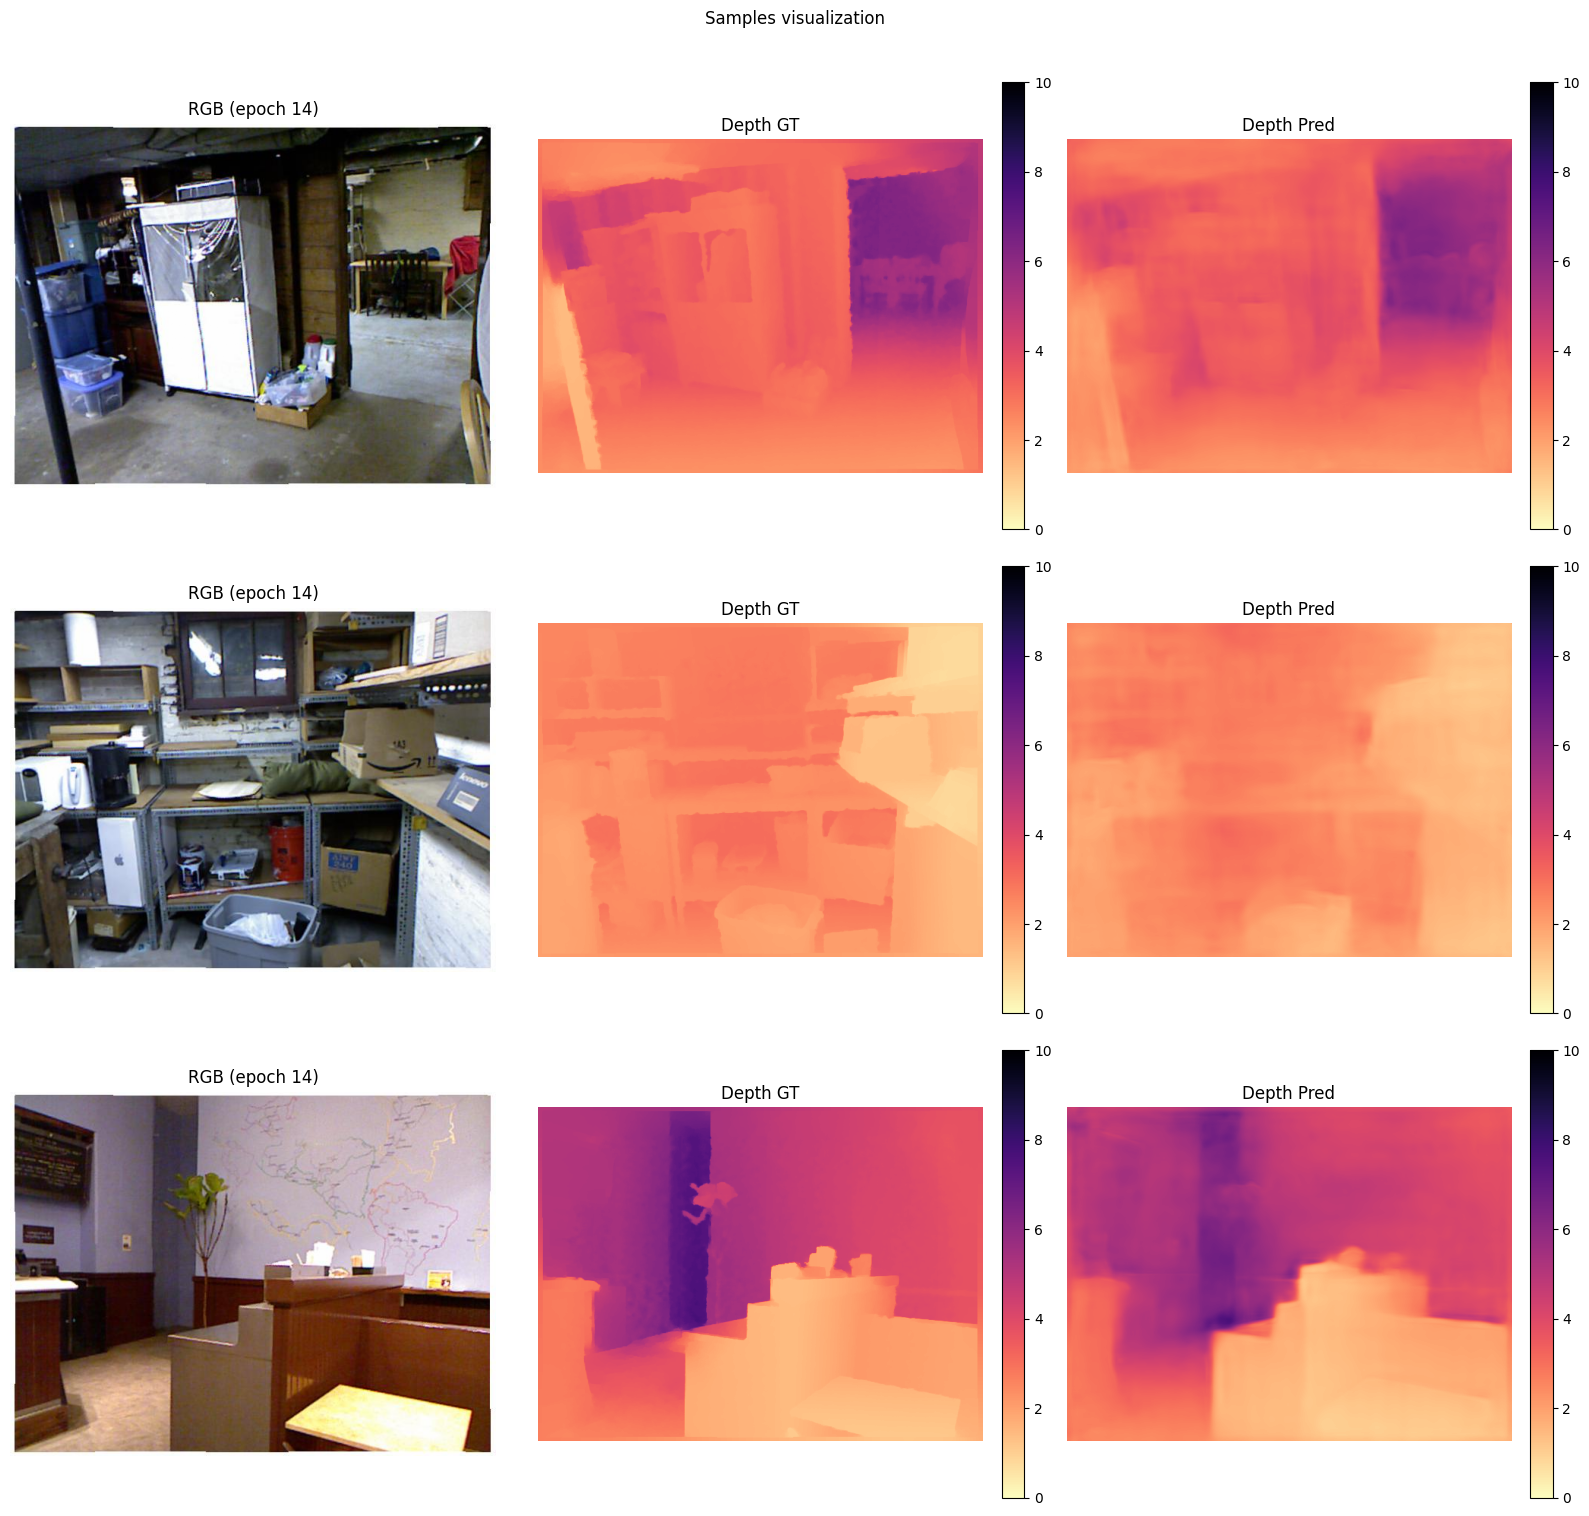

In [ ]:
import os
import numpy as np
from tqdm.auto import tqdm
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
import torchvision.transforms.functional as TF
from torchvision.transforms import InterpolationMode
from IPython.display import clear_output
# -----------------------------
# تنظیمات
# -----------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MAX_DEPTH = 10.0
BATCH_SIZE = 10
EPOCHS = 14
GRAD_CLIP = 1.0

VIS_EVERY = 2  # هر چند ایپاک یک بار نمایش بده
SAMPLE_RGB_PATHS = [
    "/kaggle/input/nyu-depth-v2/nyu_data/data/nyu2_train/basement_0001a_out/1.jpg",
    "/kaggle/input/nyu-depth-v2/nyu_data/data/nyu2_train/basement_0001b_out/1.jpg",
    "/kaggle/input/nyu-depth-v2/nyu_data/data/nyu2_train/cafe_0001a_out/101.jpg",
]

# -----------------------------
# مدل، optimizer، scheduler، AMP
# -----------------------------
model = TSTDepthModel3(TSTConfig(max_depth=MAX_DEPTH)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=3e-4, betas=(0.9, 0.99))
scheduler = CosineWarmRestartsWithDecay(optimizer, T_0=10, T_mult=2, gamma=0.5, eta_min=1e-6)

use_amp = torch.cuda.is_available()
amp_device = "cuda" if use_amp else "cpu"
scaler = torch.amp.GradScaler(amp_device, enabled=use_amp)

# -----------------------------
# ذخیره بهترین مدل
# -----------------------------
save_dir = "/kaggle/working"
os.makedirs(save_dir, exist_ok=True)
best_path = os.path.join(save_dir, "best_tst_depth.pth")
best_absrel = 1e9

# -----------------------------
#    visualize
# -----------------------------
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)

def denorm_img(x_norm):
    """x_norm: (3,H,W) tensor normalized"""
    x = x_norm.detach().cpu() * IMAGENET_STD + IMAGENET_MEAN
    x = x.clamp(0, 1)
    return x

def read_depth_to_meters(depth_path, max_depth=10.0):
    """Depth png -> meters tensor (1,H,W)"""
    dimg = Image.open(depth_path)
    d = np.array(dimg)
    if d.ndim == 3:
        d = d[..., 0]
    if d.dtype == np.uint8:
        depth_m = (d.astype(np.float32) / 255.0) * float(max_depth)
    elif d.dtype == np.uint16:
        depth_m = d.astype(np.float32) / 1000.0
    else:
        depth_m = d.astype(np.float32)
    depth_t = torch.from_numpy(depth_m).unsqueeze(0)  # (1,H,W)
    return depth_t

def find_pair_by_rgb(pairs, rgb_path):
    """pairs: list of (rgb, depth)"""
    if pairs is None:
        return None
    for rp, dp in pairs:
        if rp == rgb_path:
            return (rp, dp)
    return None

from IPython.display import clear_output

@torch.no_grad()
def visualize_samples(epoch, model, train_loader, sample_rgb_paths, input_hw=(480,640), clear=True):
    model.eval()

    ds = getattr(train_loader, "dataset", None)
    pairs = getattr(ds, "pairs", None)

    if pairs is None or len(pairs) == 0:
        print("⚠️ pairs موجود نیست یا خالیه؛ نمی‌تونم مسیر RGB/Depth رو پیدا کنم.")
        return

    H, W = input_hw
    vmin, vmax = 0.0, MAX_DEPTH

    if clear:
        clear_output(wait=True)

    n = len(sample_rgb_paths)
    fig, axs = plt.subplots(n, 3, figsize=(16, 5*n), squeeze=False)

    for i, rgb_pick in enumerate(sample_rgb_paths):
        chosen = find_pair_by_rgb(pairs, rgb_pick)

        if chosen is None:
            low_pick = rgb_pick.lower()
            for rp, dp in pairs[:5000]:
                if low_pick in rp.lower():
                    chosen = (rp, dp)
                    break

        if chosen is None:
            print(f"⚠️ این سمپل پیدا نشد: {rgb_pick}")
            continue

        rgb_path, depth_path = chosen

        rgb_pil = Image.open(rgb_path).convert("RGB")
        gt_depth = read_depth_to_meters(depth_path, max_depth=MAX_DEPTH)

        rgb_in = TF.resize(rgb_pil, (H, W), interpolation=InterpolationMode.BILINEAR)
        gt_in  = TF.resize(gt_depth, (H, W), interpolation=InterpolationMode.BILINEAR)

        x = TF.to_tensor(rgb_in)
        x_norm = (x - IMAGENET_MEAN) / IMAGENET_STD
        x_b = x_norm.unsqueeze(0).to(device)

        with torch.amp.autocast(device_type=amp_device, enabled=use_amp):
            pred = model(x_b)["pred_d"]  # (1,1,H,W)

        pred = pred[0,0].float().detach().cpu().numpy()
        gt_show = gt_in[0].float().detach().cpu().numpy()
        rgb_show = x.permute(1,2,0).detach().cpu().numpy()

        axs[i,0].imshow(rgb_show)
        axs[i,0].set_title(f"RGB (epoch {epoch})")
        axs[i,0].axis("off")

        im1 = axs[i,1].imshow(gt_show, cmap="magma_r", vmin=vmin, vmax=vmax)
        axs[i,1].set_title("Depth GT")
        axs[i,1].axis("off")
        fig.colorbar(im1, ax=axs[i,1], fraction=0.046, pad=0.04)

        im2 = axs[i,2].imshow(pred, cmap="magma_r", vmin=vmin, vmax=vmax)
        axs[i,2].set_title("Depth Pred")
        axs[i,2].axis("off")
        fig.colorbar(im2, ax=axs[i,2], fraction=0.046, pad=0.04)

    fig.suptitle("Samples visualization", y=1.01)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    model.train()

# -----------------------------
# Train loop
# -----------------------------
for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} [train]", leave=False)
    for it, batch in enumerate(pbar):
        img  = batch["image"].to(device, non_blocking=True)
        gt   = batch["depth"].to(device, non_blocking=True)
        mask = batch["mask"].to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type=amp_device, enabled=use_amp):
            pred = model(img)["pred_d"]
            loss = tst_scale_invariant_log_loss(pred, gt, mask, lam=0.5)

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)

        scaler.step(optimizer)
        scaler.update()

        # scheduler per-iter (مثل قبل)
        scheduler.step((epoch - 1) + (it + 1) / len(train_loader))

        running_loss += loss.item()
        pbar.set_postfix(loss=running_loss / (it + 1), lr=optimizer.param_groups[0]["lr"])

    train_loss = running_loss / max(1, len(train_loader))

    # -------- val --------
    model.eval()
    val_loss = 0.0
    m_absrel = 0.0
    m_rmse   = 0.0
    m_d1     = 0.0
    n_batches = 0

    for batch in tqdm(val_loader, desc=f"Epoch {epoch}/{EPOCHS} [val]", leave=False):
        img  = batch["image"].to(device, non_blocking=True)
        gt   = batch["depth"].to(device, non_blocking=True)
        mask = batch["mask"].to(device, non_blocking=True)

        with torch.no_grad():
            pred = model(img)["pred_d"]
            loss = tst_scale_invariant_log_loss(pred, gt, mask, lam=0.5)

        val_loss += loss.item()

        mets = depth_metrics(pred, gt, mask)
        m_absrel += mets["abs_rel"].item()
        m_rmse   += mets["rmse"].item()
        m_d1     += mets["delta1"].item()
        n_batches += 1

    val_loss /= max(1, n_batches)
    m_absrel /= max(1, n_batches)
    m_rmse   /= max(1, n_batches)
    m_d1     /= max(1, n_batches)

    print(f"[Epoch {epoch:03d}] "
          f"train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | "
          f"AbsRel={m_absrel:.4f} RMSE={m_rmse:.4f} d1={m_d1:.4f}")

    # -------- save best --------
    if m_absrel < best_absrel:
        best_absrel = m_absrel
        torch.save({
            "epoch": epoch,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "best_absrel": best_absrel,
        }, best_path)
        print("✅ saved best to:", best_path, "best_absrel:", best_absrel)

    # -------- visualize  VIS_EVERY  --------
    if (epoch % VIS_EVERY) == 0:
        visualize_samples(epoch, model, train_loader, SAMPLE_RGB_PATHS, input_hw=(480,640))